# 02 — ECG Preprocessing

Dataset MathWorks yang diunduh pada notebook 01 sudah memiliki frekuensi sampling 128 Hz dan panjang rekaman 65.536 sampel. Karena itu, notebook ini **tidak melakukan resampling ulang**. Notebook memvalidasi ukuran, frekuensi sampling, dan menyimpan salinan sinyal untuk tahap denoising.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") if Path("..").exists() else Path(".")
DATA_DIR = ROOT / "data"
WORK_DIR = DATA_DIR / "processed"
RAW_DIR = DATA_DIR / "raw"

CLASS_NAMES = ["CHF", "NSR"]
FS_TARGET = 128
RECORD_LENGTH = 65536
IN_MANIFEST = WORK_DIR / "manifest.csv"
OUT_DIR = WORK_DIR / "02_preprocessed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not IN_MANIFEST.exists():
    raise FileNotFoundError("Manifest tidak ditemukan. Jalankan notebook 01 terlebih dahulu.")


In [2]:
manifest = pd.read_csv(IN_MANIFEST)
unknown_labels = set(manifest["label"].dropna()) - set(CLASS_NAMES)
if unknown_labels:
    print("Label yang dikecualikan:", sorted(unknown_labels))
manifest = manifest[manifest["label"].isin(CLASS_NAMES)].reset_index(drop=True)
if set(manifest["label"]) != set(CLASS_NAMES):
    raise ValueError(f"Manifest harus memuat CHF dan NSR; ditemukan: {sorted(set(manifest['label']))}")
processed_rows = []

for _, row in manifest.iterrows():
    x = np.load(row["path"]).astype(np.float32)

    if len(x) != RECORD_LENGTH:
        raise ValueError(
            f"{row['record_id']} memiliki {len(x)} sampel; "
            f"seharusnya {RECORD_LENGTH}."
        )
    if not np.all(np.isfinite(x)):
        raise ValueError(f"{row['record_id']} mengandung NaN/Inf.")

    out_path = OUT_DIR / f"{row['record_id']}.npy"
    np.save(out_path, x)

    processed_rows.append({
        "record_id": row["record_id"],
        "label": row["label"],
        "path": str(out_path.resolve()),
        "original_fs": FS_TARGET,
        "resampled_fs": FS_TARGET,
        "original_samples": len(x),
        "processed_samples": len(x)
    })

proc_manifest = pd.DataFrame(processed_rows)
proc_manifest.to_csv(OUT_DIR / "manifest_preprocessed.csv", index=False)

print("Jumlah rekaman:", len(proc_manifest))
print("Bentuk setiap sinyal:", (RECORD_LENGTH,))
display(proc_manifest.groupby("label").size().rename("jumlah"))


Jumlah rekaman: 66
Bentuk setiap sinyal: (65536,)


label
CHF    30
NSR    36
Name: jumlah, dtype: int64

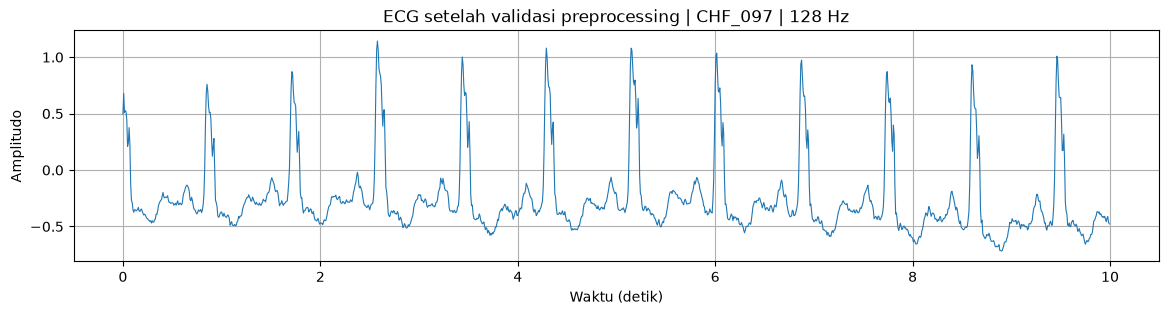

In [3]:
row = proc_manifest.iloc[0]
x = np.load(row["path"])
n = 10 * FS_TARGET
plt.figure(figsize=(14, 3))
plt.plot(np.arange(n) / FS_TARGET, x[:n], linewidth=0.8)
plt.title(f"ECG setelah validasi preprocessing | {row['record_id']} | {FS_TARGET} Hz")
plt.xlabel("Waktu (detik)")
plt.ylabel("Amplitudo")
plt.grid(True)
plt.show()


**Catatan:** data sudah berada pada 128 Hz dan panjang 65.536 sampel dari paket dataset MathWorks. Jangan melakukan resampling ulang karena dapat mengubah sinyal tanpa kebutuhan.
